# Rains of Renewal (Templar)

Rains of Renewal is a self-only heal over time. It restores a flat amount of HP every second for
60 s, using the same per-tick formula as Parasite's damage. The spell item is also its own
cooldown: it cannot be recast while it is running, but it can be recast as soon as it expires.

| | |
|---|---|
| Class | Templar |
| Target | Self only |
| Cost | 50 endurance, spent **before** the spell attaches |
| Cooldown | none beyond the 60 s duration (the HoT item carries the skill's own temp) |
| Landing roll | none; only `add_spell` can refuse it (all 20 spell slots hold stronger spells) |
| Duration | 60 s, one tick per second |
| Healing | `a_hp += max(1, ⌊3p/4⌋)` HP per second, capped at max HP |
| Source | `server/src/driver/skill/templar.rs::skill_rains_of_renewal`; tick in `server/src/state/stats.rs` |

---

# Formula

The item stores the caster's raw modified skill (minimum 1). Immunity and race are not applied,
and the item is never re-checked. Every second:

$$
\text{heal} = \max\!\left(1,\ \left\lfloor \tfrac{3p}{4} \right\rfloor\right)\ \text{HP/s}
\qquad
\text{total} = 60\cdot\text{heal}
\qquad
\text{HP per endurance} = \frac{60\cdot\text{heal}}{50}
$$

| Quantity | Breakpoint |
|---|---|
| Floor | 1 HP/s for $p \le 1$ |
| Raise cap | 78 HP/s at skill 105 (4,680 HP per cast) |
| Ceiling | none (linear to skill 200 and beyond) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 60
END_COST = 50

# Model

In [2]:
def rains_hps(p):
    return mm.dot_tick(np.maximum(1, p), "parasite")


def rains_total(p):
    return DURATION_S * rains_hps(p)


def melee_dps(wv=40, strength=80, armor=0, attacks_per_s=2.025, p_hit=0.6):
    """Incoming DPS from one melee attacker (normal hits only, Δ = 0)."""
    return attacks_per_s * p_hit * mm.melee_hit_hp(wv, strength, armor)

# Validation

`rains_of_renewal_applies_a_buff_that_blocks_recasting`:

- `a_end` 49,000 is refused.
- At skill 0 the stored power is 1, the item lasts `TICKS*60`, and 120,000 drops to 70,000.
- A second cast while the item is active spends nothing and keeps the same item.

In [3]:
assert 49_000 < END_COST * 1000 and 120_000 - END_COST * 1000 == 70_000
assert max(1, 0) == 1 and rains_hps(1) == 1
assert mm.TICKS * DURATION_S == 2160
assert rains_hps(105) == 78 and rains_total(105) == 4680
print("Rains of Renewal model OK")

Rains of Renewal model OK


# Plots

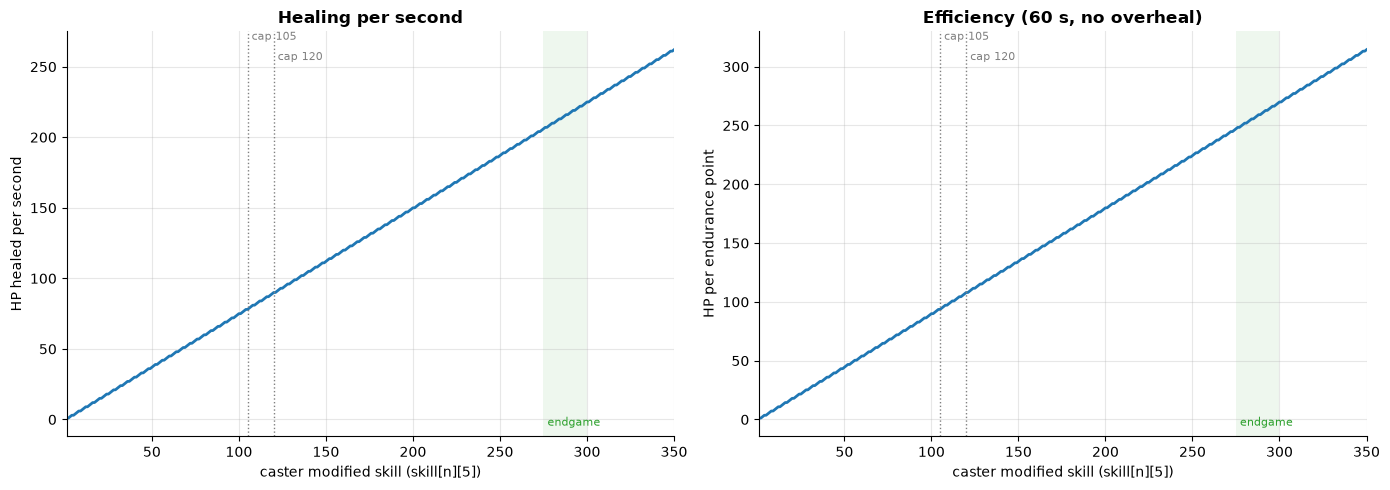

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(P, rains_hps(P))
mm.skill_axis(ax, "HP healed per second", "Healing per second")
mm.mark_caps(ax)

ax = axes[1]
ax.plot(P, rains_total(P) / END_COST)
mm.skill_axis(ax, "HP per endurance point", "Efficiency (60 s, no overheal)")
mm.mark_caps(ax)
plt.tight_layout()

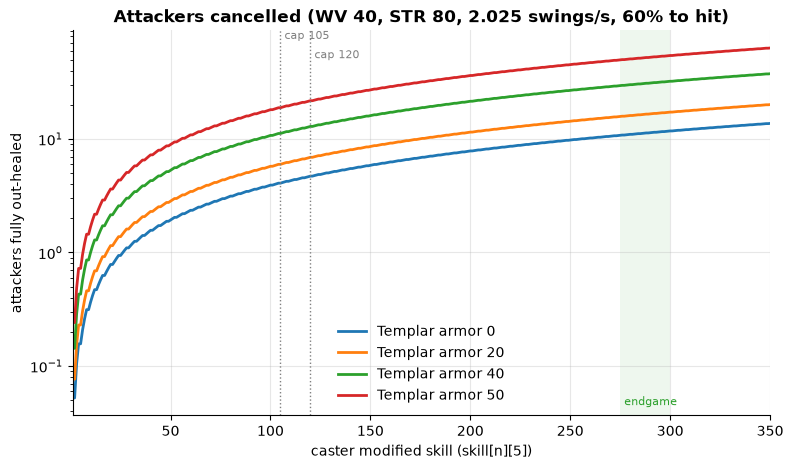

In [5]:
# How many equal melee attackers Rains cancels out, by the Templar's armor.
fig, ax = plt.subplots()
for armor in (0, 20, 40, 50):
    ax.plot(P, rains_hps(P) / melee_dps(armor=armor), label=f"Templar armor {armor}")
mm.skill_axis(ax, "attackers fully out-healed", "Attackers cancelled (WV 40, STR 80, 2.025 swings/s, 60% to hit)")
ax.set_yscale("log")
mm.mark_caps(ax)
ax.legend()

# Observations

- At skill 105 Rains heals 78 HP/s, or 4,680 HP per
  cast. One WV-40 STR-80 attacker swinging 2 times per second at 60% to hit deals 19 HP/s
  against armor 0 and 13 HP/s against armor 20. Rains therefore cancels about four attackers
  at armor 0, six at armor 20 and eleven at armor 40.
- The only lockout is the item itself, so the Templar can recast the moment
  it expires. That is 50 endurance per 60 s.
- No immunity or resist check, no target to
  interrupt, and nothing to dispel it short of `add_spell` eviction. Endurance is spent before
  `add_spell`, so a refused attach wastes the 50 endurance.
- Healing grows linearly and never saturates, so every
  raise past the cap still adds 0.75 HP/s.
- Scale the heal down, for example $p/4$ (26 HP/s at 105). Or make it a
  shorter burst with a separate cooldown so it cannot run back to back.